# IRWA 2026 - Part 2: Indexing and Evaluation

This notebook implements an inverted index and a search engine using
the processed corpus from Part 1.

The search engine uses conjunctive queries (AND) and ranks the matching
documents using TF-IDF scores.

We also implement several evaluation metrics to measure the performance
of the search engine using the provided validation labels and five
additional test queries.

The functions are in `myapp/search/algorithms.py` (index, search and ranking)
and `myapp/search/evaluation.py` (metrics), so that later parts and the web app can reuse them.
See `README.md` for run instructions.

## 1. Load the processed corpus

Loads the documents pre-processed in Part 1 from
`data/processed_corpus.jsonl`.

The same text preprocessing function is used for both
documents and search queries.

In [1]:
from pathlib import Path
import sys
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Find the repository root
ROOT = Path.cwd().resolve()

while not (ROOT / "web_app.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Repository root not found")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from myapp.search.preprocessing import load_processed_corpus, build_terms
from myapp.search.algorithms import create_index_tfidf, search_and, search_in_corpus
from myapp.search.evaluation import evaluate_query, mean_average_precision, mean_reciprocal_rank

DATA_PATH = ROOT / "data" / "processed_corpus.jsonl"
VALIDATION_PATH = ROOT / "data" / "validation_labels.csv"
PART_DIR = ROOT / "project_progress" / "part_2"
OUT_DIR = PART_DIR / "output"
FIG_DIR = PART_DIR / "figures"
EXPERT_PATH = OUT_DIR / "expert_labels.csv"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

# Load the processed documents from Part 1
docs = load_processed_corpus(DATA_PATH)
print("Number of documents:", len(docs))
print("Example query:", build_terms("men slim jeans blue"))

Number of documents: 28080
Example query: ['men', 'slim', 'jean', 'blue']


## 2. Inverted index

Builds an inverted index using the terms stored in `all_terms`
(title, description, brand, category, sub_category, product_details and seller).

For each term, the index stores the documents where it appears and the
positions of the term in each document. While building it we also compute
the normalized term frequency (tf) of each term in each document, the
document frequency (df) and the inverse document frequency (idf) of each term.

In [2]:
index, tf, df, idf = create_index_tfidf(docs)
print("Number of documents:", len(docs))
print("Number of unique terms:", len(index))

# Example: first 3 postings of the term "kurta" ([pid, positions])
for pid, positions in index["kurta"][:3]:
    print(pid, list(positions))
print("df of 'kurta':", df["kurta"], " idf:", idf["kurta"])

Number of documents: 28080
Number of unique terms: 6822
ETHFYB46QHB6PMYG [1, 17, 34, 56, 66, 72, 78]
KTAFTMYM2VYNZACZ [5, 9, 20, 41, 42]
ETHFSRVEN6JGSBYG [1, 10, 16, 20]
df of 'kurta': 1196  idf: 3.1561


## 3. Conjunctive search and TF-IDF ranking

### 3.1 Conjunctive search (AND)

The search engine retrieves only documents containing all the
processed query terms.

The matching documents are obtained by intersecting the posting
lists of the query terms.

In [3]:
# Example: number of documents of each query term, and of the intersection (AND)
query_terms = build_terms("men slim jeans blue")
for term in query_terms:
    print(term, "->", df[term], "documents")
print("Documents with ALL the terms:", len(search_and(query_terms, index)))

men -> 14250 documents
slim -> 5679 documents
jean -> 2436 documents
blue -> 7709 documents
Documents with ALL the terms: 224


### 3.2 TF-IDF ranking

The matching documents are ranked using TF-IDF scores.

Term frequency measures how often a query term appears in a document,
while inverse document frequency gives more importance to terms
that are less common in the corpus.

As in Practice Session 1, the tf of a term is its count divided by the length of the
document's count vector, so long documents are not favoured just because they repeat
words, and idf = ln(N / df). The query is represented in the same way, and the score
of a document is the dot product of the query and document vectors.

Documents with higher scores appear first in the ranking.

### 3.3 Test queries

To choose the queries we looked at the most popular terms in the titles
(number of titles that contain each term) and combined them into queries
for different kinds of products: shirts, t-shirts, ethnic wear, jackets and shoes.

In [4]:
# Count in how many titles each term appears (set() so a term counts once per title)
title_df = Counter()
for terms in docs["title_terms"]:
    title_df.update(set(terms))
pd.DataFrame(title_df.most_common(30), columns=["term", "titles"]).T

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
term,women,men,tshirt,neck,solid,round,print,pack,blue,fit,...,grey,regular,cotton,sweatshirt,dark,design,self,color,block,green
titles,13041,13021,12247,11444,9215,8301,8106,4787,4282,3923,...,1913,1754,1647,1343,1333,1324,1320,1295,1282,1276


In [5]:
test_queries = {
    "Q1": "men cotton casual shirt",
    "Q2": "women black round neck tshirt",
    "Q3": "women cotton kurta",
    "Q4": "women blue denim jacket",
    "Q5": "men running shoes",
}

for query_id, query_text in test_queries.items():
    ranked = search_in_corpus(query_text, index, tf, idf)
    print(f"{query_id}: {query_text}")
    print(f"Matching documents: {len(ranked)}")
    print("---------------------------------------")

Q1: men cotton casual shirt
Matching documents: 1442
---------------------------------------


Q2: women black round neck tshirt
Matching documents: 1189
---------------------------------------
Q3: women cotton kurta
Matching documents: 575
---------------------------------------
Q4: women blue denim jacket
Matching documents: 27
---------------------------------------
Q5: men running shoes
Matching documents: 76
---------------------------------------


In [6]:
def show_search_results(query, k=10):
    """
    Search a query and show its top k results

    Argument:
    query -- query text
    k -- number of results to show

    Returns:
    result_table -- DataFrame with pid, tf-idf score, title and sub_category
    """
    ranked = search_in_corpus(query, index, tf, idf, top_k=k)  # list of [score, pid]
    result_table = pd.DataFrame(ranked, columns=["tfidf_score", "pid"])
    result_table["title"] = result_table["pid"].map(docs["title"])
    result_table["sub_category"] = result_table["pid"].map(docs["sub_category"])
    result_table["tfidf_score"] = result_table["tfidf_score"].round(3)
    return result_table[["pid", "tfidf_score", "title", "sub_category"]]


all_top10 = []
for query_id, query_text in test_queries.items():
    print(f"{query_id}: {query_text}")
    result_table = show_search_results(query_text)
    display(result_table)
    result_table.insert(0, "query_id", query_id)
    all_top10.append(result_table)
pd.concat(all_top10).to_csv(OUT_DIR / "test_queries_top10.csv", index=False)

Q1: men cotton casual shirt


,pid,tfidf_score,title,sub_category
0,SHTF4EHGZUJHPB7C,1.246,Women Slim Fit Solid Casual Shirt,Topwear
1,SHTF4EHGZM3YK4R5,1.220,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
2,SHTF4EHGU2ZMCY3J,1.220,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
3,SHTF4EHGT7Y87GS4,1.220,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
4,SHTF4EHGCKNVVYUB,1.220,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
5,SHTF4EHG2KU74RX5,1.220,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
6,SHTFP3TTJREVUQTG,1.218,Men Slim Fit Solid Spread Collar Casual Shirt,Topwear
7,SHTF4EHGHJCGXDKS,1.218,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
8,SHTF4EHG2PHCGQ5N,1.218,Men Slim Fit Solid Mandarin Collar Casual Shirt,Topwear
9,SHTF4EHGZEZQHFMA,1.217,Women Slim Fit Solid Mandarin Collar Casual Shirt,Topwear


Q2: women black round neck tshirt


,pid,tfidf_score,title,sub_category
0,TSHFPT66HZR2HYGN,0.869,Printed Women Round Neck Black T-Shirt,Topwear
1,TSHFZWJMK4HG7R4X,0.804,Printed Women Round Neck Black T-Shirt,Topwear
2,TSHFKGPVJTVJQU3W,0.797,Solid Women Round Neck Black T-Shirt,Topwear
3,TSHFUTG2TZSYDWTP,0.796,Printed Women Round Neck Black T-Shirt,Topwear
4,TSHFWF57CTFWRGFZ,0.793,Solid Women Round Neck Black T-Shirt,Topwear
5,TSHFYUQYXW4BY9GR,0.789,"Striped Women Round Neck Black, White T-Shirt",Topwear
6,TSHFHBQXJE8FFKVH,0.784,Self Design Women Round Neck Black T-Shirt,Topwear
7,TSHFHCNYGUTFT4HA,0.778,"Color Block Women Round Neck White, Black T-Shirt",Topwear
8,TSHFHBQNQZMJEUJE,0.778,Color Block Women Round Neck Black T-Shirt,Topwear
9,TSHFRAMFDMSBWNQT,0.771,Printed Women Round Neck Black T-Shirt,Topwear


Q3: women cotton kurta


,pid,tfidf_score,title,sub_category
0,KTAFD2UBPY9HHSY6,3.717,Women Embroidered Cotton Blend Straight Kurta (Maroon),"Kurtas, Ethnic Sets and Bottoms"
1,KTAFD2UBNRWRAQJW,3.717,Women Embroidered Cotton Blend Straight Kurta (Red),"Kurtas, Ethnic Sets and Bottoms"
2,KTAFD2UBHHZNSX2B,3.717,Women Embroidered Cotton Blend Straight Kurta (Blue),"Kurtas, Ethnic Sets and Bottoms"
3,KTAFD2U8ZGHHHNYF,3.638,Women Self Design Cotton Blend Straight Kurta (Black),"Kurtas, Ethnic Sets and Bottoms"
4,KTAFD2U8FHZRECCF,3.638,Women Self Design Cotton Blend Straight Kurta (Black),"Kurtas, Ethnic Sets and Bottoms"
5,ETHF2557ZHWRYHPT,3.599,Women Kurta and Pyjama Set Cotton Blend,"Kurtas, Ethnic Sets and Bottoms"
6,ETHF2557EGMJTGFT,3.599,Women Kurta and Pyjama Set Cotton Blend,"Kurtas, Ethnic Sets and Bottoms"
7,ETHF25572QHXAGEQ,3.599,Women Kurta and Pyjama Set Cotton Blend,"Kurtas, Ethnic Sets and Bottoms"
8,ETHF2557CGF4CUMW,3.590,Women Kurta and Pyjama Set Cotton Blend,"Kurtas, Ethnic Sets and Bottoms"
9,ETHF2557SGSWZEVH,3.566,Women Kurta and Pyjama Set Cotton Blend,"Kurtas, Ethnic Sets and Bottoms"


Q4: women blue denim jacket


,pid,tfidf_score,title,sub_category
0,JCKFMHS8ANSPXK72,4.080,Full Sleeve Printed Women Jacket,Winter Wear
1,JCKFWC5YGQENYT6B,3.907,Full Sleeve Solid Women Denim Jacket,Winter Wear
2,JCKF7KY3NQUGDHE2,3.672,Full Sleeve Solid Women Denim Casual Jacket,Winter Wear
3,JCKFZ33GHPEXHFUZ,3.628,Full Sleeve Solid Women Jacket,Winter Wear
4,JCKFXNVMGBYGXKHN,3.486,Full Sleeve Solid Women Denim Jacket,Winter Wear
5,JCKFVDPXFVQBGME7,3.402,Full Sleeve Solid Women Denim Jacket,Winter Wear
6,JCKFSHEZTYYPEMTJ,3.314,Full Sleeve Solid Women Denim Jacket,Winter Wear
7,JCKFVEUDNF3J7CWV,3.186,Full Sleeve Solid Women Jacket,Winter Wear
8,JCKFV7V7ZQ3PUSFF,3.180,Full Sleeve Washed Women Denim Riding Jacket,Winter Wear
9,JCKFVEUDBT4KKSXR,3.156,Full Sleeve Solid Women Jacket,Winter Wear


Q5: men running shoes


,pid,tfidf_score,title,sub_category
0,SHOFC585JH9RGXWG,7.255,Cricket Shoes For Women (White),Men's Footwear
1,SHOFG5TXSM7M57MY,6.399,Running Shoes For Women (Grey),Men's Footwear
2,SHOFVXGRFFD8HMBW,6.284,Party Wear For Women (Gold),Men's Footwear
3,SHOFVXGR2CZRYY7W,6.272,Party Wear For Men (Red),Men's Footwear
4,SHOFVXGRUGGSKCSU,6.259,Party Wear For Men (Blue),Men's Footwear
5,SOCFVYHYZFJ4FFNG,6.227,"Men Solid Low Cut, Peds/Footie/No-Show (Pack of 6)",Clothing Accessories
6,SHOFVXG5EYFF2H9T,5.962,Lace Up For Women (Tan),Men's Footwear
7,SHOFVXG57QNV399H,5.962,Lace Up For Women (Brown),Men's Footwear
8,SHOFWFVWRSNK5AZJ,5.962,Running Shoes For Women (Multicolor),Men's Footwear
9,SHOF98H4X8PU3EGW,5.902,Running Shoes For Women (Blue),Men's Footwear


## 4. Evaluation metrics

The metrics are implemented in `myapp/search/evaluation.py`. Each one gets the ranked
list of pids returned by the search engine and the set of relevant pids for the query.

- **Precision@K**, **Recall@K** and **F1-score@K**.
- **Average Precision@K:** sum of the precision at each position (up to K) where there
  is a relevant document, divided by min(number of relevant documents, K).
- **MAP@K:** mean of AP@K over the queries.

### Mean Reciprocal Rank (MRR)

MRR evaluates how early the first relevant document appears in the ranking.
For each query, we calculate the reciprocal of the position of its first
relevant result. MRR is the average of these values across all queries.

### Normalized Discounted Cumulative Gain (NDCG@K)

NDCG measures ranking quality by giving higher importance to relevant
documents appearing at the top of the results.

We use binary relevance labels (1 for relevant and 0 for non-relevant)
and normalize the score using the ideal ranking.

In [7]:
def prepare_rankings(labels_df, queries, label_column):
    """
    For each query, search it and keep only the judged documents, in the order of our ranking.
    Judged documents that the AND search does not return are not in the ranking.

    Argument:
    labels_df -- DataFrame with the judged documents (columns query_id, pid and the label column)
    queries -- dictionary: query_id -> query text
    label_column -- name of the column with the labels (1 relevant, 0 not relevant)

    Returns:
    rankings -- dictionary: query_id -> list of pids (best first)
    relevance -- dictionary: query_id -> set of relevant pids
    """
    rankings = {}
    relevance = {}
    for query_id, query in queries.items():
        # judged and relevant documents of the current query
        query_labels = labels_df[labels_df["query_id"] == query_id]
        judged_pids = set(query_labels["pid"])
        relevant_pids = set(query_labels[query_labels[label_column] == 1]["pid"])

        # our ranking, keeping only the judged documents
        ranked_results = search_in_corpus(query, index, tf, idf)
        ranked_pids = [pid for score, pid in ranked_results]
        rankings[query_id] = [pid for pid in ranked_pids if pid in judged_pids]
        relevance[query_id] = relevant_pids
    return rankings, relevance


def metrics_table(rankings, relevance, k):
    """
    Table with all the metrics @k of each query, rounded to 3 decimals
    (same arguments as the output of prepare_rankings)
    """
    rows = []
    for query_id in rankings:
        metrics = evaluate_query(rankings[query_id], relevance[query_id], k)
        row = {"Query": query_id}
        for name, value in metrics.items():
            row[name] = value
        rows.append(row)
    return pd.DataFrame(rows).set_index("Query").round(3)


def map_mrr_table(rankings, relevance, k_values):
    """Table with MAP@K and MRR@K for each K in k_values, rounded to 3 decimals"""
    rows = []
    for k in k_values:
        rows.append({"K": k,
                     "MAP": mean_average_precision(rankings, relevance, k),
                     "MRR": mean_reciprocal_rank(rankings, relevance, k)})
    return pd.DataFrame(rows).set_index("K").round(3)

## 5. Evaluation using the validation dataset

We evaluate our search engine using the relevance judgments provided
in the validation_labels.csv file.

These labels allow us to compare the ranked search results against
the expected relevance of the products.

In [8]:
validation_df = pd.read_csv(VALIDATION_PATH, dtype={"pid": str})

print("Number of validation records:", len(validation_df))
print("\nRelevance labels per query:")
print(validation_df.groupby("query_id")["labels"].value_counts())

Number of validation records: 40

Relevance labels per query:
query_id  labels
1         1         13
          0          7
2         0         10
          1         10
Name: count, dtype: int64


### Preparing the evaluation rankings

We use the two predefined queries from the project instructions.

Since the validation dataset contains relevance judgments for only
20 documents per query, we evaluate the ranking using the judged
documents.

We preserve the original TF-IDF ranking order and exclude unjudged
documents from the evaluation. Judged documents that the AND search does not
return are not part of the ranking, but relevant documents that were not
retrieved are still considered when calculating recall.

This approach provides an evaluation on the judged subset, although
the results may not represent performance over the entire collection.

In [9]:
validation_queries = {
    1: "women full sleeve sweatshirt cotton",
    2: "men slim jeans blue",
}
evaluation_rankings, evaluation_relevance = prepare_rankings(validation_df, validation_queries, "labels")

for query_id, query in validation_queries.items():
    print(f"Query {query_id}: {query}")
    print(f"Judged documents retrieved: {len(evaluation_rankings[query_id])} of 20")
    print(f"Relevant documents: {len(evaluation_relevance[query_id])}")
    print("---------------------------------")

Query 1: women full sleeve sweatshirt cotton
Judged documents retrieved: 20 of 20
Relevant documents: 13
---------------------------------
Query 2: men slim jeans blue
Judged documents retrieved: 8 of 20
Relevant documents: 10
---------------------------------


### 5.1 Evaluation results

The evaluation metrics are calculated at K=5 and K=10.
All results are rounded to three decimal places.

In [10]:
for k in [5, 10]:
    results_df = metrics_table(evaluation_rankings, evaluation_relevance, k)
    results_df.to_csv(OUT_DIR / f"validation_metrics_k{k}.csv")
    print(f"Evaluation at K={k}")
    display(results_df)

Evaluation at K=5


,Precision,Recall,F1,AP,RR,NDCG
Query,,,,,,
1,1.0,0.385,0.556,1.00,1.0,1.000
2,0.8,0.400,0.533,0.76,1.0,0.854


Evaluation at K=10


,Precision,Recall,F1,AP,RR,NDCG
Query,,,,,,
1,1.0,0.769,0.87,1.000,1.0,1.000
2,0.6,0.600,0.60,0.549,1.0,0.706


### 5.2 MAP and MRR

In [11]:
validation_overall = map_mrr_table(evaluation_rankings, evaluation_relevance, [5, 10])
validation_overall.to_csv(OUT_DIR / "validation_map_mrr.csv")
validation_overall

,MAP,MRR
K,,
5,0.880,1.0
10,0.775,1.0


## 6. Evaluation of our test queries

We evaluate the five test queries defined in Section 3.3.

For each query, we take the top 30 documents returned by the
search engine and assign binary relevance labels (query Q4 only has 27 results).
We judge 30 and not 20 documents because for Q5 the first relevant document
only appears after position 20.

A document is labeled as 1 if it is relevant to the query,
and 0 otherwise. The rule used for each query is written in the README.

In [12]:
# If the labels file does not exist yet, create it with an empty "relevance" column to fill in
if not EXPERT_PATH.exists():
    expert_rows = []
    for query_id, query in test_queries.items():
        ranked_results = search_in_corpus(query, index, tf, idf, top_k=30)
        for rank, (score, pid) in enumerate(ranked_results, start=1):
            document = docs.loc[pid]
            description = document["description"]
            if not isinstance(description, str):
                description = ""
            expert_rows.append({
                "query_id": query_id,
                "query": query,
                "rank": rank,
                "pid": pid,
                "title": document["title"],
                "sub_category": document["sub_category"],
                "description": description[:200],
                "relevance": ""
            })
    pd.DataFrame(expert_rows).to_csv(EXPERT_PATH, index=False)
    print("Expert labels file created: fill in the relevance column and run the notebook again.")
else:
    print("Existing expert labels file found. The file has not been overwritten.")

Existing expert labels file found. The file has not been overwritten.


### 6.1 Manual relevance judgments

The relevance judgments were assigned by examining
the product information for each query (title, sub_category and product_details).

In [13]:
expert_df = pd.read_csv(EXPERT_PATH, dtype={"pid": str})

assert expert_df["relevance"].notna().all()
assert expert_df["relevance"].isin([0, 1]).all()
print("Manual relevance labels verified!")

expert_df.groupby("query_id")["relevance"].agg(judged="count", relevant="sum")

Manual relevance labels verified!


,judged,relevant
query_id,,
Q1,30,18
Q2,30,27
Q3,30,22
Q4,27,13
Q5,30,5


### 6.2 Evaluation results for the test queries

We calculate Precision, Recall, F1-score, Average Precision, Reciprocal Rank and
NDCG at K=5 and K=10 for each of the five test queries.
Recall is computed against the relevant documents among the judged ones.

All results are rounded to three decimal places.

In [14]:
custom_rankings, custom_relevance = prepare_rankings(expert_df, test_queries, "relevance")

for k in [5, 10]:
    results_df = metrics_table(custom_rankings, custom_relevance, k)
    results_df.to_csv(OUT_DIR / f"test_queries_metrics_k{k}.csv")
    print(f"Evaluation at K={k}")
    display(results_df)

Evaluation at K=5


,Precision,Recall,F1,AP,RR,NDCG
Query,,,,,,
Q1,0.8,0.222,0.348,0.543,0.5,0.661
Q2,1.0,0.185,0.312,1.000,1.0,1.000
Q3,1.0,0.227,0.370,1.000,1.0,1.000
Q4,1.0,0.385,0.556,1.000,1.0,1.000
Q5,0.0,0.000,0.000,0.000,0.0,0.000


Evaluation at K=10


,Precision,Recall,F1,AP,RR,NDCG
Query,,,,,,
Q1,0.8,0.444,0.571,0.617,0.5,0.716
Q2,0.8,0.296,0.432,0.743,1.0,0.852
Q3,0.5,0.227,0.312,0.500,1.0,0.649
Q4,1.0,0.769,0.870,1.000,1.0,1.000
Q5,0.0,0.000,0.000,0.000,0.0,0.000


### 6.3 MAP and MRR

In [15]:
custom_overall = map_mrr_table(custom_rankings, custom_relevance, [5, 10])
custom_overall.to_csv(OUT_DIR / "test_queries_map_mrr.csv")
custom_overall

,MAP,MRR
K,,
5,0.709,0.7
10,0.572,0.7


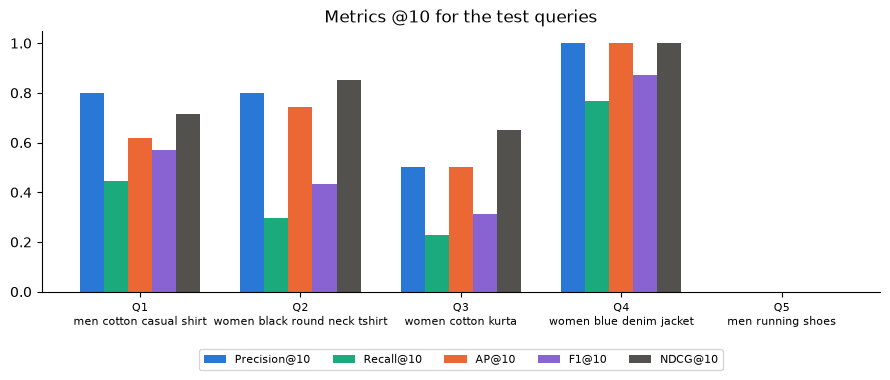

In [16]:
# Metrics @10 of each test query
at_10 = metrics_table(custom_rankings, custom_relevance, 10)
metric_names = ["Precision", "Recall", "AP", "F1", "NDCG"]
colors = ["#2a78d6", "#1baa7b", "#eb6834", "#8a63d2", "#52514e"]

# One group of bars per query, one bar per metric
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(at_10))  # position of each query on the x axis
width = 0.15
for i in range(len(metric_names)):
    ax.bar(x + i * width, at_10[metric_names[i]], width, label=metric_names[i] + "@10", color=colors[i])
ax.set_xticks(x + 2 * width)
ax.set_xticklabels([q + "\n" + test_queries[q] for q in at_10.index], fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_title("Metrics @10 for the test queries")
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "test_queries_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Discussion and limitations

### 7.1 Evaluation metrics

Each evaluation metric provides different information about the
performance of the search engine.

- **Precision@K:** Measures the proportion of relevant documents
  among the top K retrieved results.

- **Recall@K:** Measures the proportion of known relevant documents
  retrieved within the top K results.

- **F1-score@K:** Combines Precision and Recall into a single score
  using their harmonic mean.

- **Average Precision@K:** Evaluates the ranking by considering
  the precision at each position where a relevant document appears.

- **MAP:** Calculates the mean Average Precision across multiple
  queries, providing an overall measure of ranking quality.

- **MRR:** Measures how early the first relevant document appears
  in the ranking.

- **NDCG:** Evaluates ranking quality by giving more importance
  to relevant documents appearing in the first positions.

### 7.2 Results analysis

The evaluation results show differences in performance depending
on the query.

For the validation queries, query 1 gets 1.000 in every metric at K=10:
all 20 judged documents contain every query term and the relevant ones
are ranked first. Query 2 is harder: only 8 of the 20 judged documents
contain all the query terms (most of the others are women's jeans without
the term "men"), so Precision@10 and Recall@10 are 0.600. Three of these
women's jeans are labeled as relevant, which suggests some noise in the labels.

For our test queries, Q4 ranks only relevant documents in the top 10.
Q2 reaches Precision@10 = 0.800; its errors are t-shirts with two colours
(e.g. black and white).

Q1 has Precision@10 = 0.800 but RR = 0.500, because the first result is a
women's shirt. Its `product_details` contain a list of keywords
("Men's Party Wear shirts", "Men Casual Shirts"), so it matches the term "men".

For Q3, Precision@10 is 0.500 because kurta sets (kurta and pyjama/churidar)
repeat the word "kurta" and are ranked above single kurtas.

Q5 gets 0.000 in all metrics: the top 20 results are other kinds of shoes (cricket,
party wear, lace-ups, loafers, sneakers), many of them for women, and socks. The first
men's running shoe appears at position 21. Every shoe has
the sub_category "Men's Footwear", so the term "men" matches all of them.

The overall MAP@10 is 0.572 and MRR@10 is 0.700 for the test queries
(0.775 and 1.000 for the validation queries).

### 7.3 System limitations and possible improvements

Although the search engine retrieves relevant documents, there
are several limitations that could be improved.

**1. Strict AND queries**

Our search engine uses conjunctive queries, meaning that a document
must contain all query terms to be retrieved.

This can exclude relevant products that do not contain every
term in the query.

A possible improvement would be to support OR queries or more
flexible matching strategies.

**2. No field weighting**

The inverted index uses `all_terms`, combining terms from the
title, description, brand, category and other text fields.

Currently, all fields contribute equally to the TF-IDF score.
However, a term appearing in the title may be more important
than the same term appearing in the description or seller field.
For example, every shoe has the sub_category "Men's Footwear", so women's shoes match
the term "men" in Q5.

A possible solution would be to implement field-weighted TF-IDF,
giving more importance to the title and product category.

**3. Limitations of TF-IDF ranking**

TF-IDF ranks documents based on term frequency and inverse
document frequency, but it does not understand the meaning
of the query.

Our tf is normalized by the document length, but documents that
repeat a query term many times can still get higher scores.
Near-duplicate products (the same product in several colours) also
fill many of the top positions.

Possible improvements include a ranking algorithm such as BM25
and grouping near-duplicate products.

**4. Query formulation**

The search engine depends on the exact terms used in the query,
after preprocessing.

Synonyms and different ways of describing the same product
may lead to missing relevant results.

Query expansion or semantic search could help retrieve
documents with similar meanings.

**5. Indexing strategy**

The index stores the positions of each term, but they are not used yet,
and it does not distinguish between fields.

A more advanced index could store separate postings for
different fields and use the positions for phrase searches
(for example "running shoes" as two consecutive words).

**6. Evaluation limitations**

The validation dataset contains only 20 judged documents per
predefined query. For our five test queries, we evaluated only
the top 30 retrieved documents.

This limits the conclusions we can draw about the entire
collection of 28,080 products.

A possible improvement would be to evaluate more documents,
including results from different ranking positions, and use
additional human relevance judgments.

## 8. Conclusions

In this part of the project, we implemented an inverted index
using the processed corpus from Part 1.

We developed a search engine based on conjunctive queries and
TF-IDF ranking to retrieve and rank fashion products.

We also implemented several evaluation metrics, including
Precision, Recall, F1-score, Average Precision, MAP, MRR
and NDCG.

The search engine was evaluated using the two predefined
queries and five additional test queries.

The results show that TF-IDF can provide useful rankings,
although performance depends on the query and the relevance
of the retrieved documents.

The main limitations are related to strict AND matching,
the lack of field weighting and the limited number of
relevance judgments.

Future improvements could include more flexible queries,
field-weighted ranking and better evaluation datasets.

## 9. Saved files
- `output/expert_labels.csv`: our relevance judgments for the test queries
- `output/test_queries_top10.csv`: top 10 results of each test query
- `output/validation_metrics_k5.csv`, `output/validation_metrics_k10.csv`, `output/validation_map_mrr.csv`
- `output/test_queries_metrics_k5.csv`, `output/test_queries_metrics_k10.csv`, `output/test_queries_map_mrr.csv`
- `figures/test_queries_metrics.png`